# Praktikum 3 - SVM Data Overlapping

**Nama:** Agus  
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2/praktikum-3)

Kode utama di bawah mengikuti blok kode dan urutan modul. Penyesuaian terbatas pada lokasi dataset, kompatibilitas API, dan perbaikan error. Analisis tambahan ditempatkan setelah seluruh langkah modul.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
np.random.seed(42)
print("Kernel:", sys.executable)

Kernel: /Volumes/External/miniconda3/envs/ml-praktikum/bin/python


## Langkah 1 - Import Library dan Buat Fungsi Plotting

In [2]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC
from sklearn.datasets import make_blobs

In [3]:
# buat sebuah fungsi untuk menampilkan fitting data

def plot_svc_decision_function(model, ax=None, plot_support=True):
    
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)
    
    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])
    
    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Langkah 2 - Buat Data Dummy

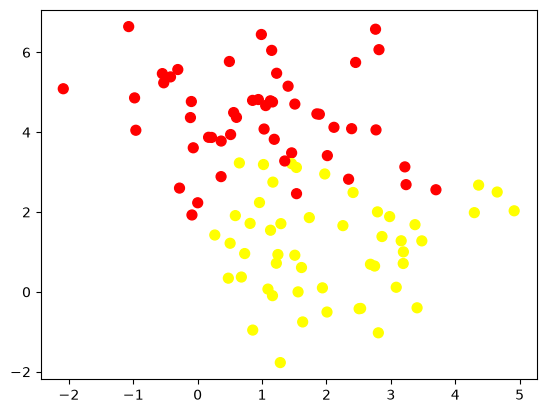

In [4]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=1.2)
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

## Langkah 3 - Analisis Dampak Tunning

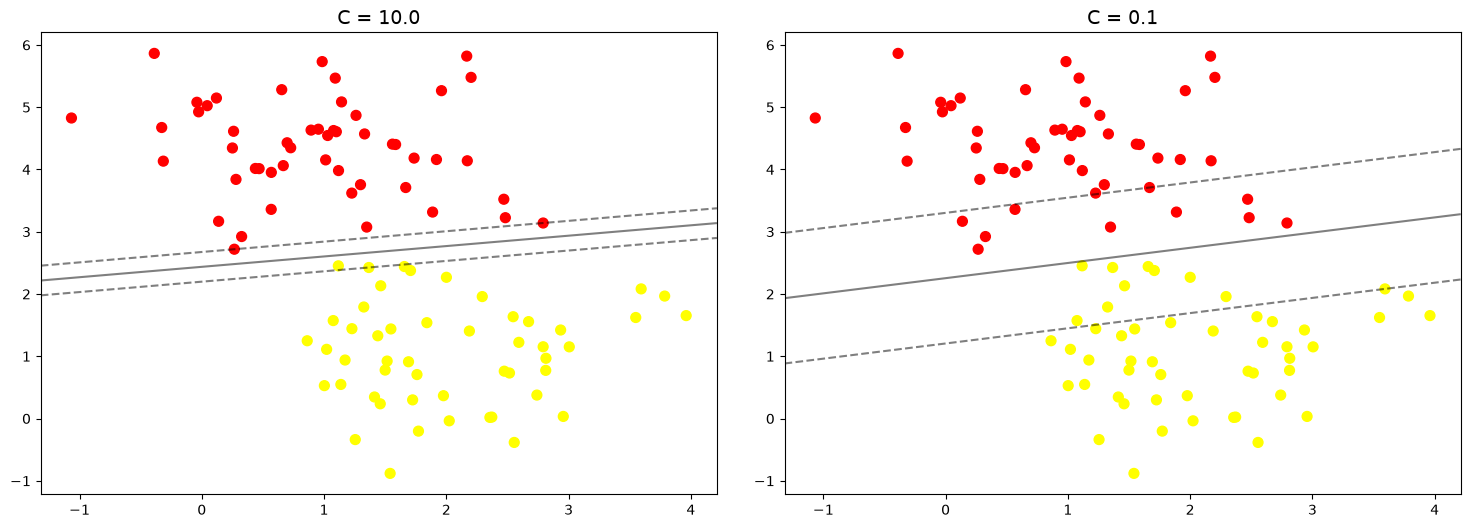

In [5]:
X, y = make_blobs(n_samples=100, centers=2,
                  random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for axi, C in zip(ax, [10.0, 0.1]):
    model = SVC(kernel='linear', C=C).fit(X, y)
    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
    plot_svc_decision_function(model, axi)
    axi.scatter(model.support_vectors_[:, 0],
                model.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none');
    axi.set_title('C = {0:.1f}'.format(C), size=14)

## Evaluasi dan analisis tambahan

In [6]:
import pandas as pd
rows = []
for value in [10.0, 0.1]:
    fitted = SVC(kernel='linear', C=value).fit(X, y)
    rows.append({'C': value, 'Support vectors': int(fitted.n_support_.sum()),
                 'Lebar margin 2/||w||': 2 / np.linalg.norm(fitted.coef_[0]),
                 'Akurasi training': fitted.score(X, y)})
display(pd.DataFrame(rows))

,C,Support vectors,Lebar margin 2/||w||,Akurasi training
0,10.0,4,0.470181,1.0
1,0.1,20,2.038014,1.0


C besar memberikan penalti pelanggaran margin lebih tinggi; C kecil mengizinkan pelanggaran untuk margin lebih lebar. Perbandingan memakai dataset dengan cluster_std=0.8 yang sama, sebagaimana bagian tuning pada modul.